# 08 — Modelos de Machine Learning

## Objetivo

Entrenar y comparar modelos con **validación cruzada anidada** (5 folds
externos × 3 internos). La selección de características y los hiperparámetros
se ajustan dentro de cada fold externo. Las predicciones out-of-fold (OOF) se
usan para la evaluación del notebook 09.

## 0. Configuración

In [34]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
DATA, V2, REP = ROOT / "data", ROOT / "data" / "v2", ROOT / "reports"
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 160)

In [37]:
from src.artifacts import ensure_artifacts
ensure_artifacts(
    [DATA / "features_tbx11k_v2.csv"],
    [sys.executable, "scripts/rebuild_features.py"],
    "Features v2.",
)
ensure_artifacts(
    [V2 / "summary_models.csv", V2 / "folds__texture__lr.csv",
     V2 / "nested_threshold__texture__lr.csv", REP / "v2" / "roc_pr_lr.png",
     REP / "v2" / "confusion_lr_texture.png", REP / "v2" / "umbral_lr_texture.png",
     ROOT / "models" / "v2_lr_texture_manifest.json"],
    [sys.executable, "scripts/run_modeling_v2.py"],
    "Modelado v2 (puede tardar ~20 min).",
)


[WindowsPath('c:/Users/juana/OneDrive/Documentos/CAD_TBX11K/data/v2/summary_models.csv'),
 WindowsPath('c:/Users/juana/OneDrive/Documentos/CAD_TBX11K/data/v2/folds__texture__lr.csv'),
 WindowsPath('c:/Users/juana/OneDrive/Documentos/CAD_TBX11K/data/v2/nested_threshold__texture__lr.csv'),
 WindowsPath('c:/Users/juana/OneDrive/Documentos/CAD_TBX11K/reports/v2/roc_pr_lr.png'),
 WindowsPath('c:/Users/juana/OneDrive/Documentos/CAD_TBX11K/reports/v2/confusion_lr_texture.png'),
 WindowsPath('c:/Users/juana/OneDrive/Documentos/CAD_TBX11K/reports/v2/umbral_lr_texture.png'),
 WindowsPath('c:/Users/juana/OneDrive/Documentos/CAD_TBX11K/models/v2_lr_texture_manifest.json')]

## 1. Resultados de la CV anidada

In [26]:
summary = pd.read_csv(V2 / "summary_models.csv")
summary.round(3)

,feature_set,model,n_features,balacc_0.5,sens_0.5,spec_0.5,ap_0.5,auc_0.5,balacc_youden,sens_youden,spec_youden,ap_youden
0,texture,dummy,96,0.488,0.075,0.901,0.095,0.488,0.500,1.000,0.000,0.095
1,texture,lr,96,0.810,0.774,0.846,0.591,0.889,0.813,0.845,0.782,0.591
2,texture,svm,96,0.782,0.584,0.980,0.725,0.939,0.876,0.852,0.900,0.725
3,texture,rf,96,0.784,0.594,0.974,0.735,0.929,0.857,0.855,0.860,0.735
4,texture,xgb,96,0.845,0.774,0.917,0.741,0.927,0.856,0.850,0.862,0.741
5,hog,lr,1764,0.774,0.760,0.788,0.463,0.851,0.776,0.755,0.797,0.463
6,texture_hog,lr,1860,0.849,0.811,0.887,0.693,0.921,0.853,0.822,0.883,0.693
7,shape,lr,64,0.643,0.668,0.619,0.191,0.691,0.647,0.714,0.580,0.191
8,shape_quality,lr,68,0.661,0.652,0.669,0.280,0.725,0.668,0.621,0.714,0.280
9,context,lr,352,0.899,0.874,0.924,0.816,0.954,0.901,0.871,0.930,0.816


## 2. Curvas ROC y Precision-Recall (LR)

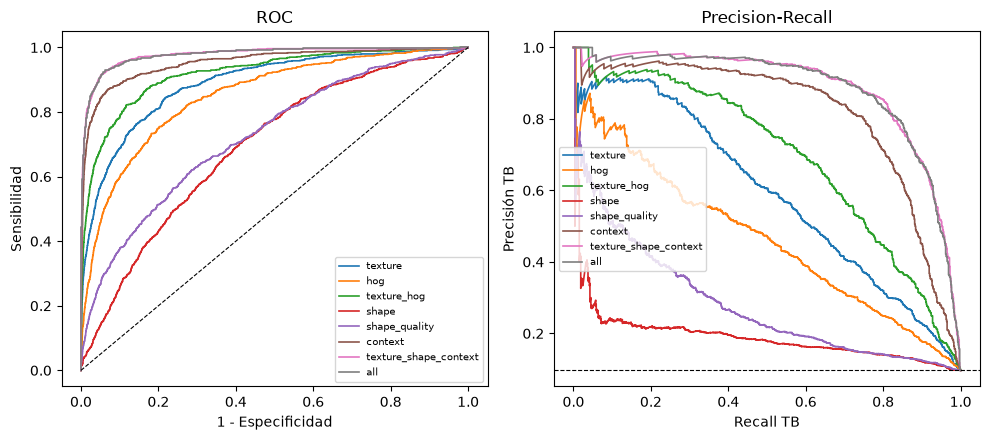

In [27]:
display(Image(filename=str(REP / "v2" / "roc_pr_lr.png")))

## 3. Matriz de confusión del modelo recomendado

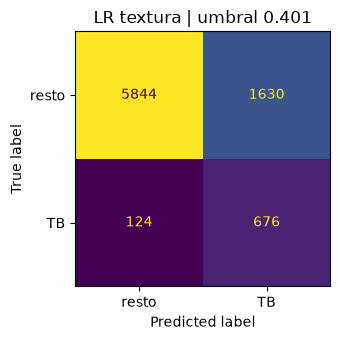

In [28]:
display(Image(filename=str(REP / "v2" / "confusion_lr_texture.png")))

## 4. Umbral clínico

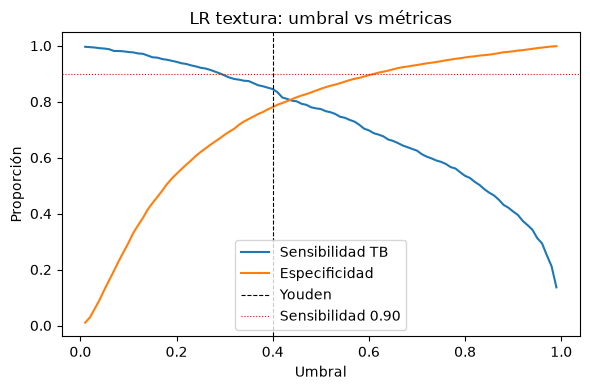

In [29]:
display(Image(filename=str(REP / "v2" / "umbral_lr_texture.png")))

## 5. Hiperparámetros elegidos por fold

In [30]:
folds = pd.read_csv(V2 / "folds__texture__lr.csv")
folds[["fold", "balanced_accuracy", "sensitivity_tb", "specificity", "ap", "best_params"]]

,fold,balanced_accuracy,sensitivity_tb,specificity,ap,best_params
0,1,0.794586,0.8875,0.701672,0.620638,"{'clf__C': 10.0, 'clf__class_weight': 'balance..."
1,2,0.766033,0.8625,0.669565,0.601463,"{'clf__C': 10.0, 'clf__class_weight': 'balance..."
2,3,0.793374,0.9125,0.674247,0.590751,"{'clf__C': 10.0, 'clf__class_weight': 'balance..."
3,4,0.766409,0.9375,0.595318,0.582951,"{'clf__C': 0.1, 'clf__class_weight': 'balanced..."
4,5,0.789475,0.9250,0.653949,0.570365,"{'clf__C': 10.0, 'clf__class_weight': 'balance..."


## 6. Umbral anidado (sin optimismo)

In [31]:
nested = pd.read_csv(V2 / "nested_threshold__texture__lr.csv")
nested[["fold", "threshold", "balanced_accuracy", "sensitivity_tb", "specificity", "ap"]].round(3)

,fold,threshold,balanced_accuracy,sensitivity_tb,specificity,ap
0,1,0.296,0.795,0.888,0.702,0.621
1,2,0.290,0.766,0.862,0.670,0.601
2,3,0.289,0.793,0.912,0.674,0.591
3,4,0.261,0.766,0.938,0.595,0.583
4,5,0.273,0.789,0.925,0.654,0.570


El umbral se elige **dentro de cada fold de entrenamiento** con el objetivo
sensibilidad ≥ 0.90 y se aplica al fold externo. Así no se reutiliza el test
para elegir el umbral.

## 7. Modelo final

In [32]:
manifest = json.loads((ROOT / "models" / "v2_lr_texture_manifest.json").read_text(encoding="utf-8"))
{k: manifest[k] for k in ["model", "feature_set", "n_features_input",
                          "n_features_selected", "best_params",
                          "prevalence", "threshold_youden", "threshold_sens90"]}

{'model': 'LogisticRegression',
 'feature_set': 'texture',
 'n_features_input': 96,
 'n_features_selected': 48,
 'best_params': {'clf__C': 10.0,
  'clf__class_weight': 'balanced',
  'clf__max_iter': 2000,
  'clf__solver': 'lbfgs'},
 'prevalence': 0.09668842156151801,
 'threshold_youden': 0.066906,
 'threshold_sens90': 0.042774}

## Conclusiones

- LR sobre textura es el modelo recomendado: interpretable, barato y con
  probabilidades.
- XGBoost, SVM y RF se reportan como comparación; no se elige un modelo por
  una diferencia mínima sin significación.
- El umbral no se optimiza sobre las mismas predicciones OOF que se evalúan.

**Siguiente etapa:** `09_Evaluacion_Comparativa.ipynb`.